In [1]:
# Import libraries for data manipulation, numerical operations, and visualization.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data loading and variable selection

This project uses selected variables from the 2024 Behavioral Risk Factor Surveillance System (BRFSS) dataset to explore diabetes classification.

I selected variables related to demographic characteristics, BMI, general health, physical activity, smoking, heavy drinking, and reported heart disease. I included both numerical BMI (_BMI5) and BMI category (_BMI5CAT) so I could compare these two representations later.

The analysis focuses on the selected variables rather than loading every column in the original survey dataset.

In [2]:
# Select the BRFSS variables relevant to this diabetes classification project.
# Both numerical BMI and BMI category are included for a later comparison.

cols = ['DIABETE4','_AGEG5YR', '_SEX', '_BMI5', 'GENHLTH', 'EXERANY2', '_SMOKER3', '_RFDRHV9', 'CVDCRHD4', '_BMI5CAT']

In [3]:
df = pd.read_csv('brfss_survey_data_2024.csv', usecols=cols)

In [4]:
# Rename BRFSS variables to descriptive names for easier interpretation.

df = df.rename(columns={
    "DIABETE4": "diabetes_status",
    "_AGEG5YR": "age_group",
    "_SEX": "sex",
    "_BMI5": "bmi",
    "GENHLTH": "general_health",
    "EXERANY2": "exercise_30d",
    "_SMOKER3": "smoking_status",
    "_RFDRHV9": "heavy_drinker",
    "CVDCRHD4": "heart_disease",
    "_BMI5CAT": "bmi_cat"
})
print(df.columns.tolist())

['general_health', 'exercise_30d', 'heart_disease', 'diabetes_status', 'sex', 'age_group', 'bmi', 'bmi_cat', 'smoking_status', 'heavy_drinker']


In [5]:
# Check the number of rows and columns in the selected dataset.

df.shape

(457670, 10)

In [6]:
# Inspect the first few records to understand the dataset structure.

df.head()

,general_health,exercise_30d,heart_disease,diabetes_status,sex,age_group,bmi,bmi_cat,smoking_status,heavy_drinker
0,3.0,1.0,2.0,3.0,2.0,12.0,2249.0,2.0,4.0,1.0
1,1.0,1.0,1.0,3.0,1.0,13.0,2583.0,3.0,3.0,1.0
2,2.0,1.0,2.0,3.0,1.0,8.0,2253.0,2.0,1.0,1.0
3,1.0,1.0,2.0,3.0,1.0,13.0,2509.0,3.0,4.0,1.0
4,3.0,2.0,2.0,3.0,1.0,6.0,1977.0,2.0,4.0,1.0


In [7]:
# Inspect the last few records as an additional data check.
df.tail()

,general_health,exercise_30d,heart_disease,diabetes_status,sex,age_group,bmi,bmi_cat,smoking_status,heavy_drinker
457665,7.0,1.0,2.0,3.0,1.0,12.0,NaN,NaN,9.0,9.0
457666,4.0,2.0,2.0,3.0,1.0,10.0,2066.0,2.0,1.0,2.0
457667,3.0,2.0,2.0,1.0,1.0,12.0,2437.0,2.0,4.0,1.0
457668,1.0,1.0,2.0,3.0,1.0,6.0,2441.0,2.0,3.0,9.0
457669,3.0,1.0,2.0,4.0,1.0,9.0,2647.0,3.0,4.0,1.0


In [8]:
# Examine column names, data types, and non-null counts.
# BRFSS variables may be stored as floats even when they represent
# categorical or ordinal responses.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 457670 entries, 0 to 457669
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   general_health   457665 non-null  float64
 1   exercise_30d     457667 non-null  float64
 2   heart_disease    457667 non-null  float64
 3   diabetes_status  457666 non-null  float64
 4   sex              457670 non-null  float64
 5   age_group        457670 non-null  float64
 6   bmi              414633 non-null  float64
 7   bmi_cat          414633 non-null  float64
 8   smoking_status   457670 non-null  float64
 9   heavy_drinker    457670 non-null  float64
dtypes: float64(10)
memory usage: 34.9 MB


In [9]:
# Check the number of missing values in each variable.

df.isna().sum()

general_health         5
exercise_30d           3
heart_disease          3
diabetes_status        4
sex                    0
age_group              0
bmi                43037
bmi_cat            43037
smoking_status         0
heavy_drinker          0
dtype: int64

In [10]:
# BRFSS stores BMI (_BMI5) as an integer representing BMI multiplied by 100. 

print("Before converting")
print(df.bmi.head(), '\n')

# Divide by 100 to convert it to the conventional BMI scale.
df["bmi"] = df["bmi"] / 100

# confirmaing the conversion
print("After converting")
print(df.bmi.head())

Before converting
0    2249.0
1    2583.0
2    2253.0
3    2509.0
4    1977.0
Name: bmi, dtype: float64 

After converting
0    22.49
1    25.83
2    22.53
3    25.09
4    19.77
Name: bmi, dtype: float64


### Understanding BRFSS Variable Encodings

The selected BRFSS variables use numeric codes to represent survey responses. I reviewed the coding scheme before cleaning and transforming the variables.

- **general_health:** 1 Excellent, 2 Very good, 3 Good, 4 Fair, 5 Poor, 7 Don’t know, 9 Refused
- **exercise_30d & heart_disease:** 1 Yes, 2 No, 7 Don’t know, 9 Refused
- **sex:** 1 Male, 2 Female
- **age_group:** 1 = 18-24, 2 = 25-29, then every 5 years up to 13 = 80+, 14 = Don’t know/Refused
- **bmi_cat:** 1 Underweight, 2	Normal Weight, 3  Overweight, 4  Obese, Blank is missing
- **smoking_status:** 1 Everyday smoker, 2 Some-days smoker, 3 Former, 4 Never, 9 Don’t know/Refused
- **heavy_drinker:** 1 No, 2 Yes, 9 Don’t know/Refused
- **diabetes_status:** 1 diabetic, 2 only during pregnancy, 3 not diabetic, 4 prediabetes, 7 and 9 (don’t know, refused).

In [11]:
# Count the number of observation/samples present in each variable
# bmi is skip because it has many observation 

for c in df.columns:
    if c == "bmi":
        continue
    print(df[c].value_counts(dropna=False))
    print()

general_health
3.0    156229
2.0    145791
4.0     67919
1.0     64217
5.0     22204
7.0       915
9.0       390
NaN         5
Name: count, dtype: int64

exercise_30d
1.0    350061
2.0    106294
7.0       860
9.0       452
NaN         3
Name: count, dtype: int64

heart_disease
2.0    424581
1.0     28511
7.0      4297
9.0       278
NaN         3
Name: count, dtype: int64

diabetes_status
3.0    376125
1.0     65809
4.0     11307
2.0      3395
7.0       798
9.0       232
NaN         4
Name: count, dtype: int64

sex
2.0    240163
1.0    217507
Name: count, dtype: int64

age_group
10.0    47701
11.0    44774
9.0     43387
13.0    41756
12.0    36803
8.0     34936
7.0     31698
5.0     30899
1.0     29692
6.0     28968
4.0     28804
3.0     26237
2.0     23705
14.0     8310
Name: count, dtype: int64

bmi_cat
3.0    146563
4.0    139640
2.0    121053
NaN     43037
1.0      7377
Name: count, dtype: int64

smoking_status
4.0    258956
3.0    119598
1.0     33118
9.0     32022
2.0     13976
Na

## 3. Data cleaning and preprocessing
For this initial binary classification task, I retained respondents who reported diabetes (DIABETE4 = 1) and respondents who reported no diabetes (DIABETE4 = 3).

I excluded respondents reporting diabetes only during pregnancy and respondents reporting prediabetes because they do not belong to either target class defined for this model.

I then created a binary target variable:
- 0: respondent reported no diabetes
- 1: respondent reported diabetes
This target represents self-reported diabetes status, not a clinical diagnosis or future diabetes risk.

Some BRFSS variables contain special response codes such as “Don't know” and “Refused.” I removed these codes from the selected predictor variables because they do not represent valid values for the intended analysis.

This filtering approach reduces the number of available observations. The resulting dataset therefore represents respondents with valid answers to the selected variables.

In [12]:
# Filtring only the required observation

# Retain respondents who reported diabetes (1) or no diabetes (3).
# Exclude pregnancy-only diabetes and prediabetes because this
# initial model focuses on distinguishing these two groups.

df = df[df["diabetes_status"].isin([1, 3])]

# Convert to integer with 0 for non_diabetic and 1 for diabetic
df["diabetic"] = (df["diabetes_status"] == 1).astype(int)


# Remove responses coded as "Don't know" or "Refused".
# These responses cannot be reliably interpreted as valid
# predictor values for this initial modeling approach.

df = df[df["general_health"].isin([1, 2, 3, 4, 5])]
df = df[df["exercise_30d"].isin([1, 2])]
df = df[df["heart_disease"].isin([1, 2])]
df = df[df["age_group"].between(1, 13)]
df = df[df["smoking_status"].isin([1, 2, 3, 4])]
df = df[df["heavy_drinker"].isin([1, 2])]


# Drop the original diabetes-status variable after creating the binary target.
df= df.drop(columns=["diabetes_status"])

print(df.shape)
print(df["diabetic"].value_counts())

(383775, 10)
diabetic
0    326714
1     57061
Name: count, dtype: int64


In [13]:
# Recode binary variables into 0/1 indicators, categorical back to object and converting 
# to simplify, model input and interpretation.

# Female = 1, Male = 0
df["sex"] = (df["sex"] == 2).astype(int)

# Exercised in the past 30 days: Yes = 1, No = 0
df["exercise_30d"] =  (df["exercise_30d"] == 1).astype(int)

# Reported heart disease: Yes = 1, No = 0
df["heart_disease"] = (df["heart_disease"] == 1).astype(int)

# Heavy drinking: Yes = 1, No = 0
df["heavy_drinker"] = (df["heavy_drinker"] == 2).astype(int)


# Treat multi-category variables as categorical features.
df['smoking_status'] = df['smoking_status'].astype(object)


# Age group, and general health  are ordinal categorical variables
# retain their order to integer as label encoding
for c in ["general_health", "age_group"]:
    df[c] = df[c].astype(int)

# Check the resulting data types.
print(df.dtypes)

general_health      int64
exercise_30d        int64
heart_disease       int64
sex                 int64
age_group           int64
bmi               float64
bmi_cat           float64
smoking_status     object
heavy_drinker       int64
diabetic            int64
dtype: object


In [14]:
df

,general_health,exercise_30d,heart_disease,sex,age_group,bmi,bmi_cat,smoking_status,heavy_drinker,diabetic
0,3,1,0,1,12,22.49,2.0,4.0,0,0
1,1,1,1,0,13,25.83,3.0,3.0,0,0
2,2,1,0,0,8,22.53,2.0,1.0,0,0
3,1,1,0,0,13,25.09,3.0,4.0,0,0
4,3,0,0,0,6,19.77,2.0,4.0,0,0
...,...,...,...,...,...,...,...,...,...,...
457661,3,1,0,0,8,26.39,3.0,3.0,0,0
457663,2,1,0,0,4,24.66,2.0,4.0,0,0
457664,5,0,0,0,10,29.86,3.0,4.0,0,0
457666,4,0,0,0,10,20.66,2.0,1.0,1,0


In [15]:
for c in df.columns:
    if c == "bmi":
        continue
    print(df[c].value_counts(dropna=False))
    print()

general_health
3    130406
2    125586
4     55296
1     54699
5     17788
Name: count, dtype: int64

exercise_30d
1    297015
0     86760
Name: count, dtype: int64

heart_disease
0    359449
1     24326
Name: count, dtype: int64

sex
1    199368
0    184407
Name: count, dtype: int64

age_group
10    40996
11    38574
9     37001
13    34705
12    31468
8     29760
7     26764
5     26192
1     26083
4     24571
6     24526
3     22452
2     20683
Name: count, dtype: int64

bmi_cat
3.0    128735
4.0    121548
2.0    106570
NaN     20586
1.0      6336
Name: count, dtype: int64

smoking_status
4.0    235485
3.0    107245
1.0     28946
2.0     12099
Name: count, dtype: int64

heavy_drinker
0    360836
1     22939
Name: count, dtype: int64

diabetic
0    326714
1     57061
Name: count, dtype: int64



In [16]:
df.isna().sum()

general_health        0
exercise_30d          0
heart_disease         0
sex                   0
age_group             0
bmi               20586
bmi_cat           20586
smoking_status        0
heavy_drinker         0
diabetic              0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(168792)

After preprocessing, I verified the remaining missing values and checked for duplicate rows. Because every observation in the original CDC BRFSS dataset represents a unique individual respondent, identical rows appearing after column selection are not duplicates; rather, they represent different participants who shared identical responses for those specific variables. Therefore, no rows were removed during this check.

# 4 EDA

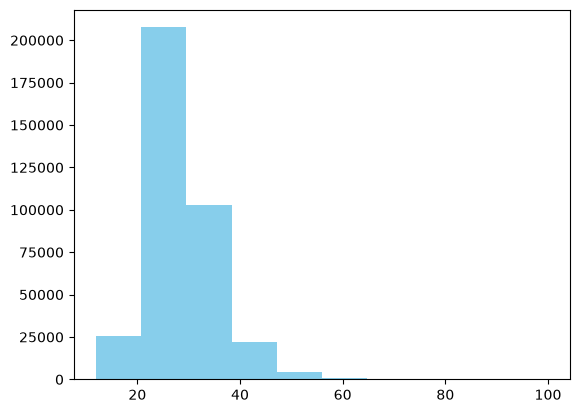

In [18]:
plt.hist(df['bmi'], color="skyblue")
plt.show()

In [19]:
df['bmi'].describe()

count    363189.000000
mean         28.520066
std           6.537135
min          12.000000
25%          24.130000
50%          27.440000
75%          31.660000
max          99.840000
Name: bmi, dtype: float64

In [20]:
missing_bmi = df.groupby("diabetic").agg(
    total=("bmi", "size"),
    missing=("bmi", lambda x: x.isna().sum())
)

missing_bmi["missing_percentage"] = (
    missing_bmi["missing"] / missing_bmi["total"] * 100
)

print(missing_bmi)

           total  missing  missing_percentage
diabetic                                     
0         326714    17646            5.401054
1          57061     2940            5.152381


In [21]:
missing_by_age = df.groupby("age_group").agg(
    total=("bmi", "size"),
    missing=("bmi", lambda x: x.isna().sum())
)

missing_by_age["missing_percentage"] = (
    missing_by_age["missing"] / missing_by_age["total"] * 100
)

print(missing_by_age)

           total  missing  missing_percentage
age_group                                    
1          26083     1771            6.789863
2          20683     1528            7.387710
3          22452     1687            7.513807
4          24571     1487            6.051850
5          26192     1428            5.452046
6          24526     1215            4.953926
7          26764     1341            5.010462
8          29760     1418            4.764785
9          37001     1788            4.832302
10         40996     2047            4.993170
11         38574     1911            4.954114
12         31468     1522            4.836659
13         34705     1443            4.157902


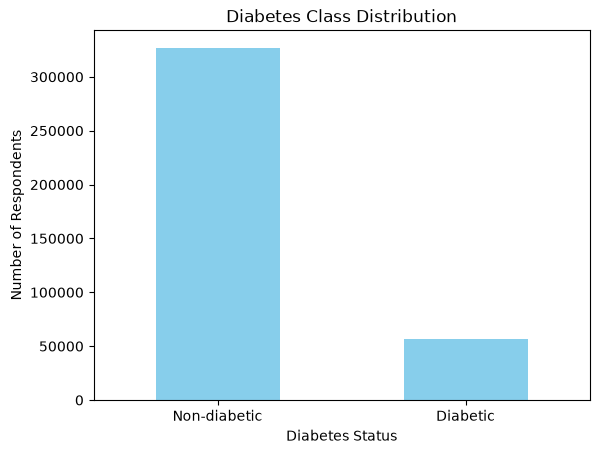

In [23]:
df["diabetic"].value_counts().plot(
    kind="bar",
    title="Diabetes Class Distribution",
    color="skyblue"
)

plt.xlabel("Diabetes Status")
plt.ylabel("Number of Respondents")
plt.xticks([0, 1], ["Non-diabetic", "Diabetic"], rotation=0)
plt.show()

In [24]:
labels = {
    "general_health": {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"},
    "sex": {0: "Male", 1: "Female"},
    "exercise_30d": {0: "No", 1: "Yes"},
    "heart_disease": {0: "No", 1: "Yes"},
    "heavy_drinker": {0: "No", 1: "Yes"},
    "smoking_status": {1: "Everyday smoker", 2: "Some-days smoker", 3: "Former", 4: "Never"},
    "bmi_cat": {1.0: "Underweight", 2.0: "Normal Weight", 3.0: "Overweight", 4.0: "Obese"},
    "age_group": ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", 
                  "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
}

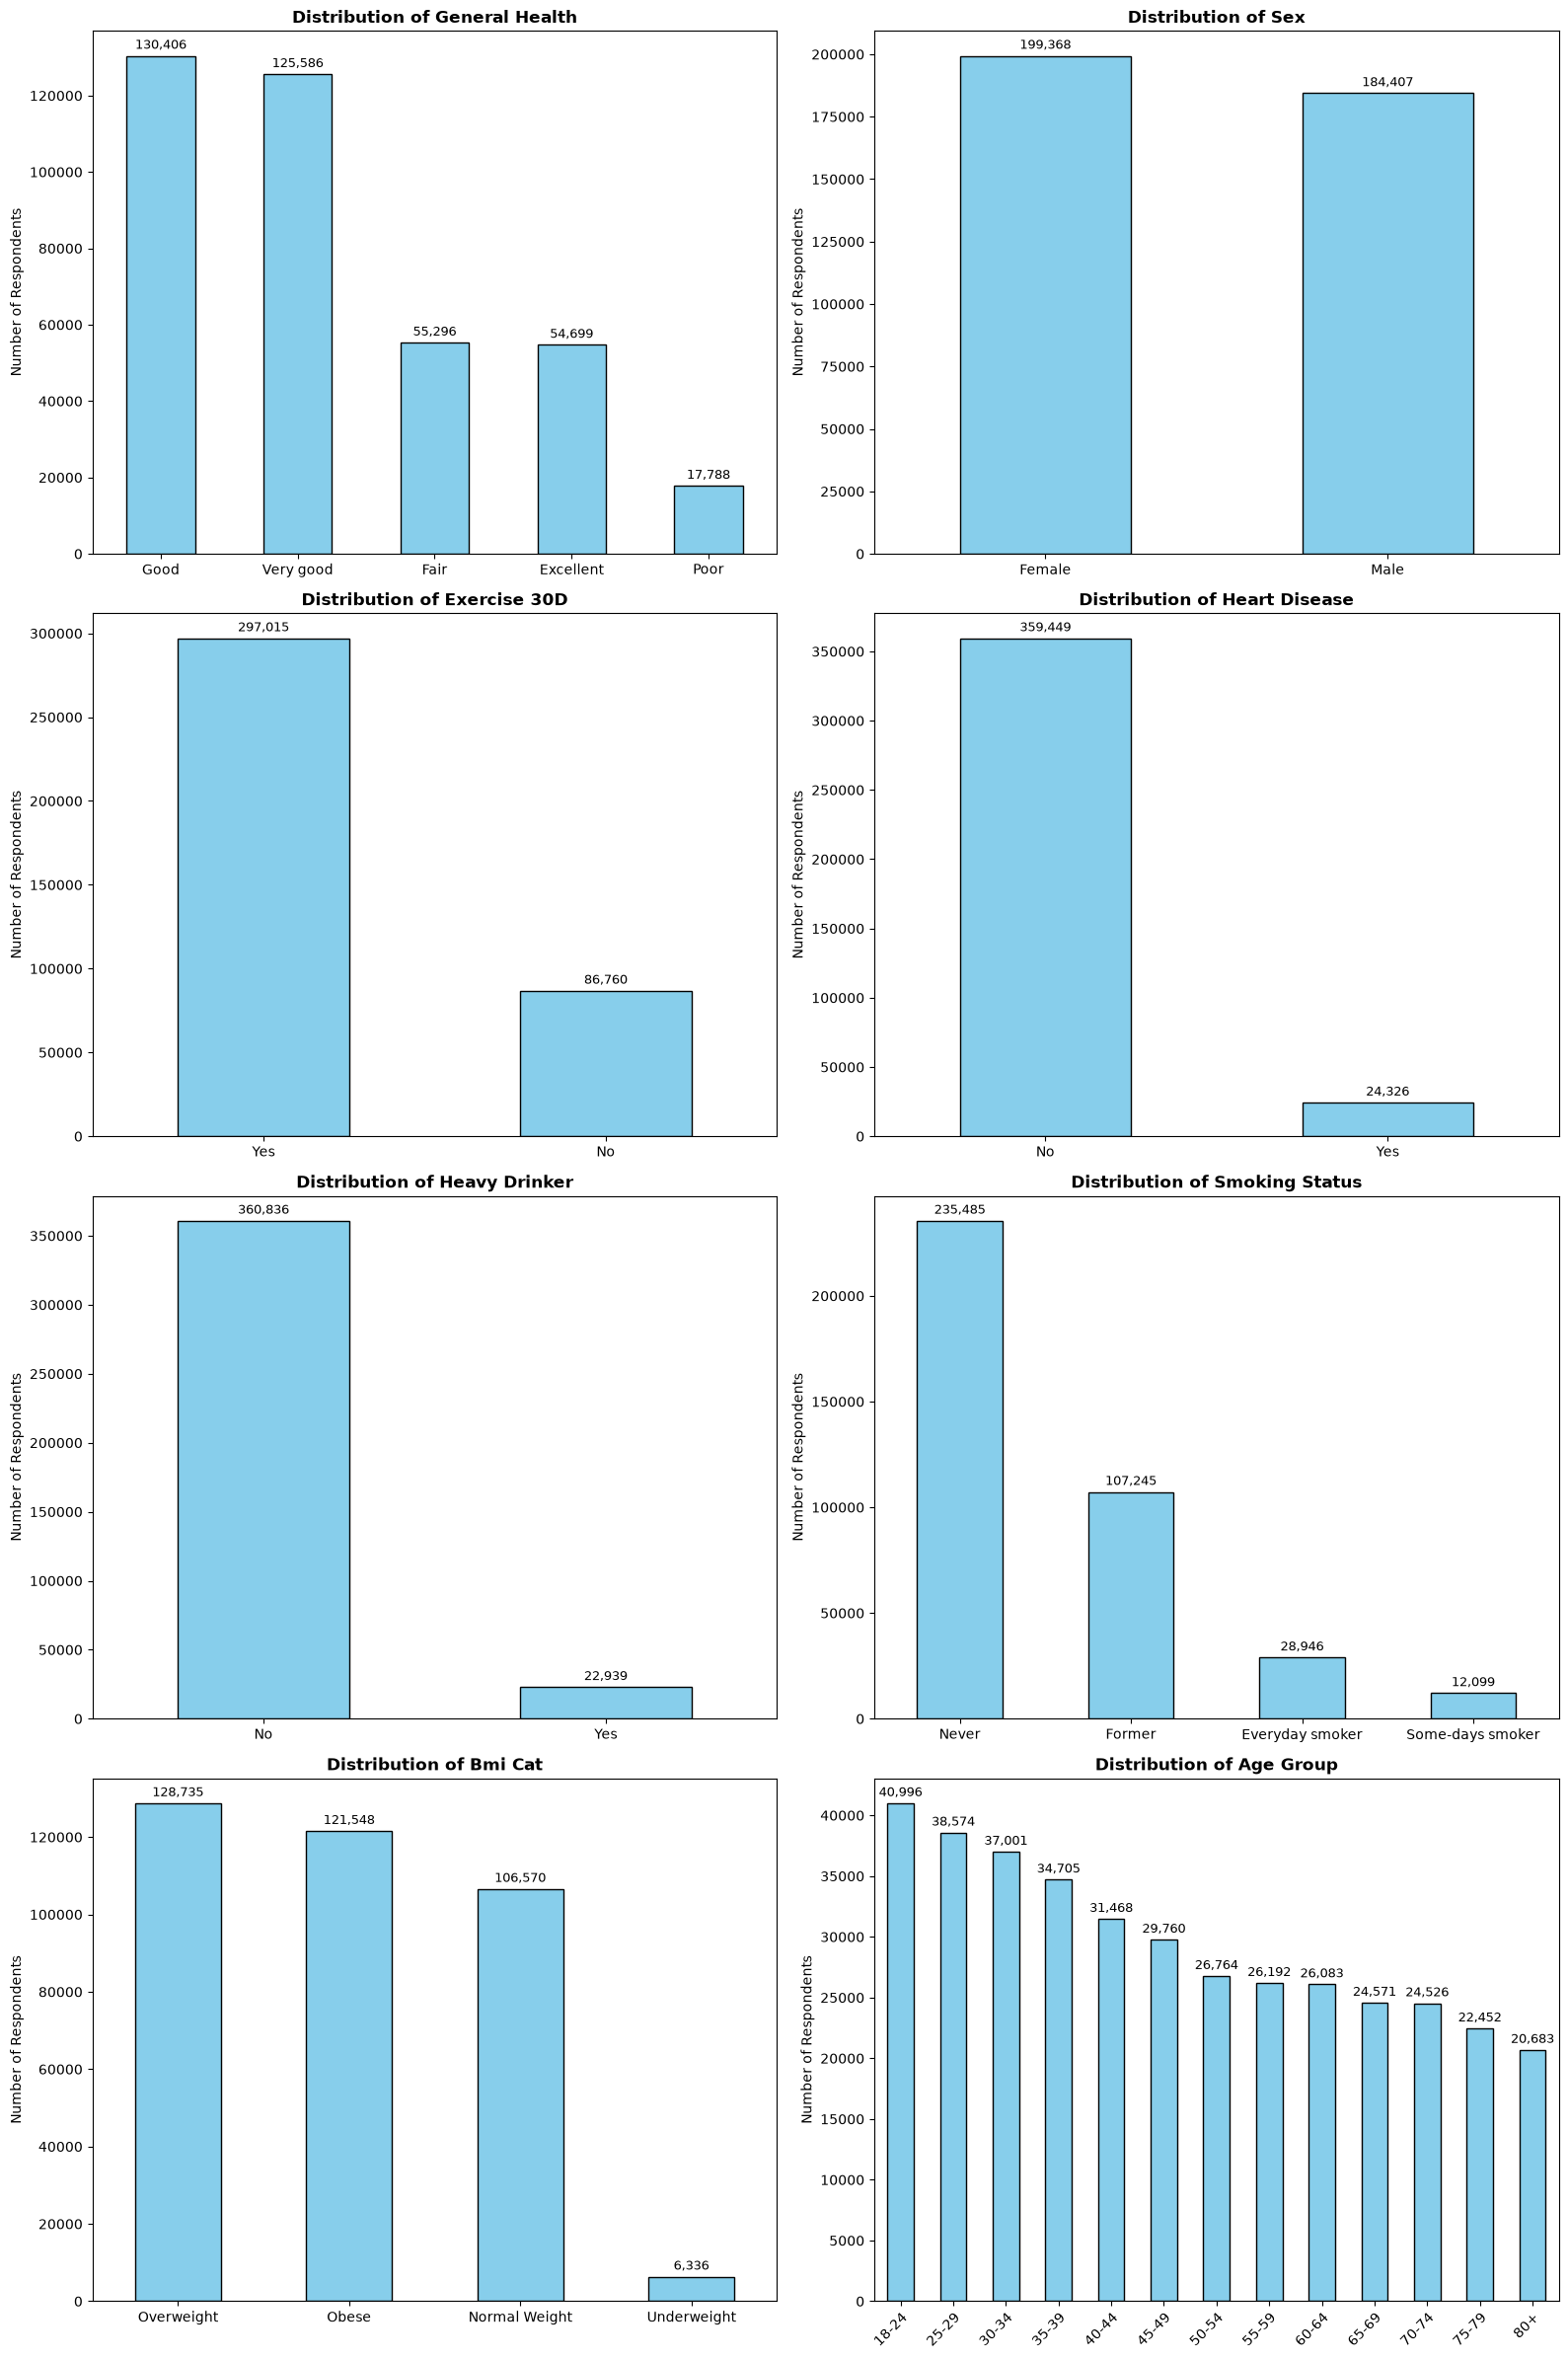

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 24)) 
axes = axes.flatten()

for i, (col, names) in enumerate(labels.items()):
    ax = axes[i]
    
    data = df[col].value_counts()
    
    if isinstance(names, dict):
        data.index = data.index.map(names)
    elif isinstance(names, list):
        data.index = names
    
    data.plot(kind="bar", ax=ax, color="skyblue", edgecolor="black")
    
    for container in ax.containers:
        ax.bar_label(container, fmt='{:,}', padding=3, fontsize=9)
    
    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    ax.set_ylabel("Number of Respondents")
    ax.set_xlabel("") 
    
    rotation_angle = 45 if col == "age_group" else 0
    ax.tick_params(axis='x', rotation=rotation_angle)
    
    if rotation_angle > 0:
        plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")

plt.tight_layout()
plt.show()


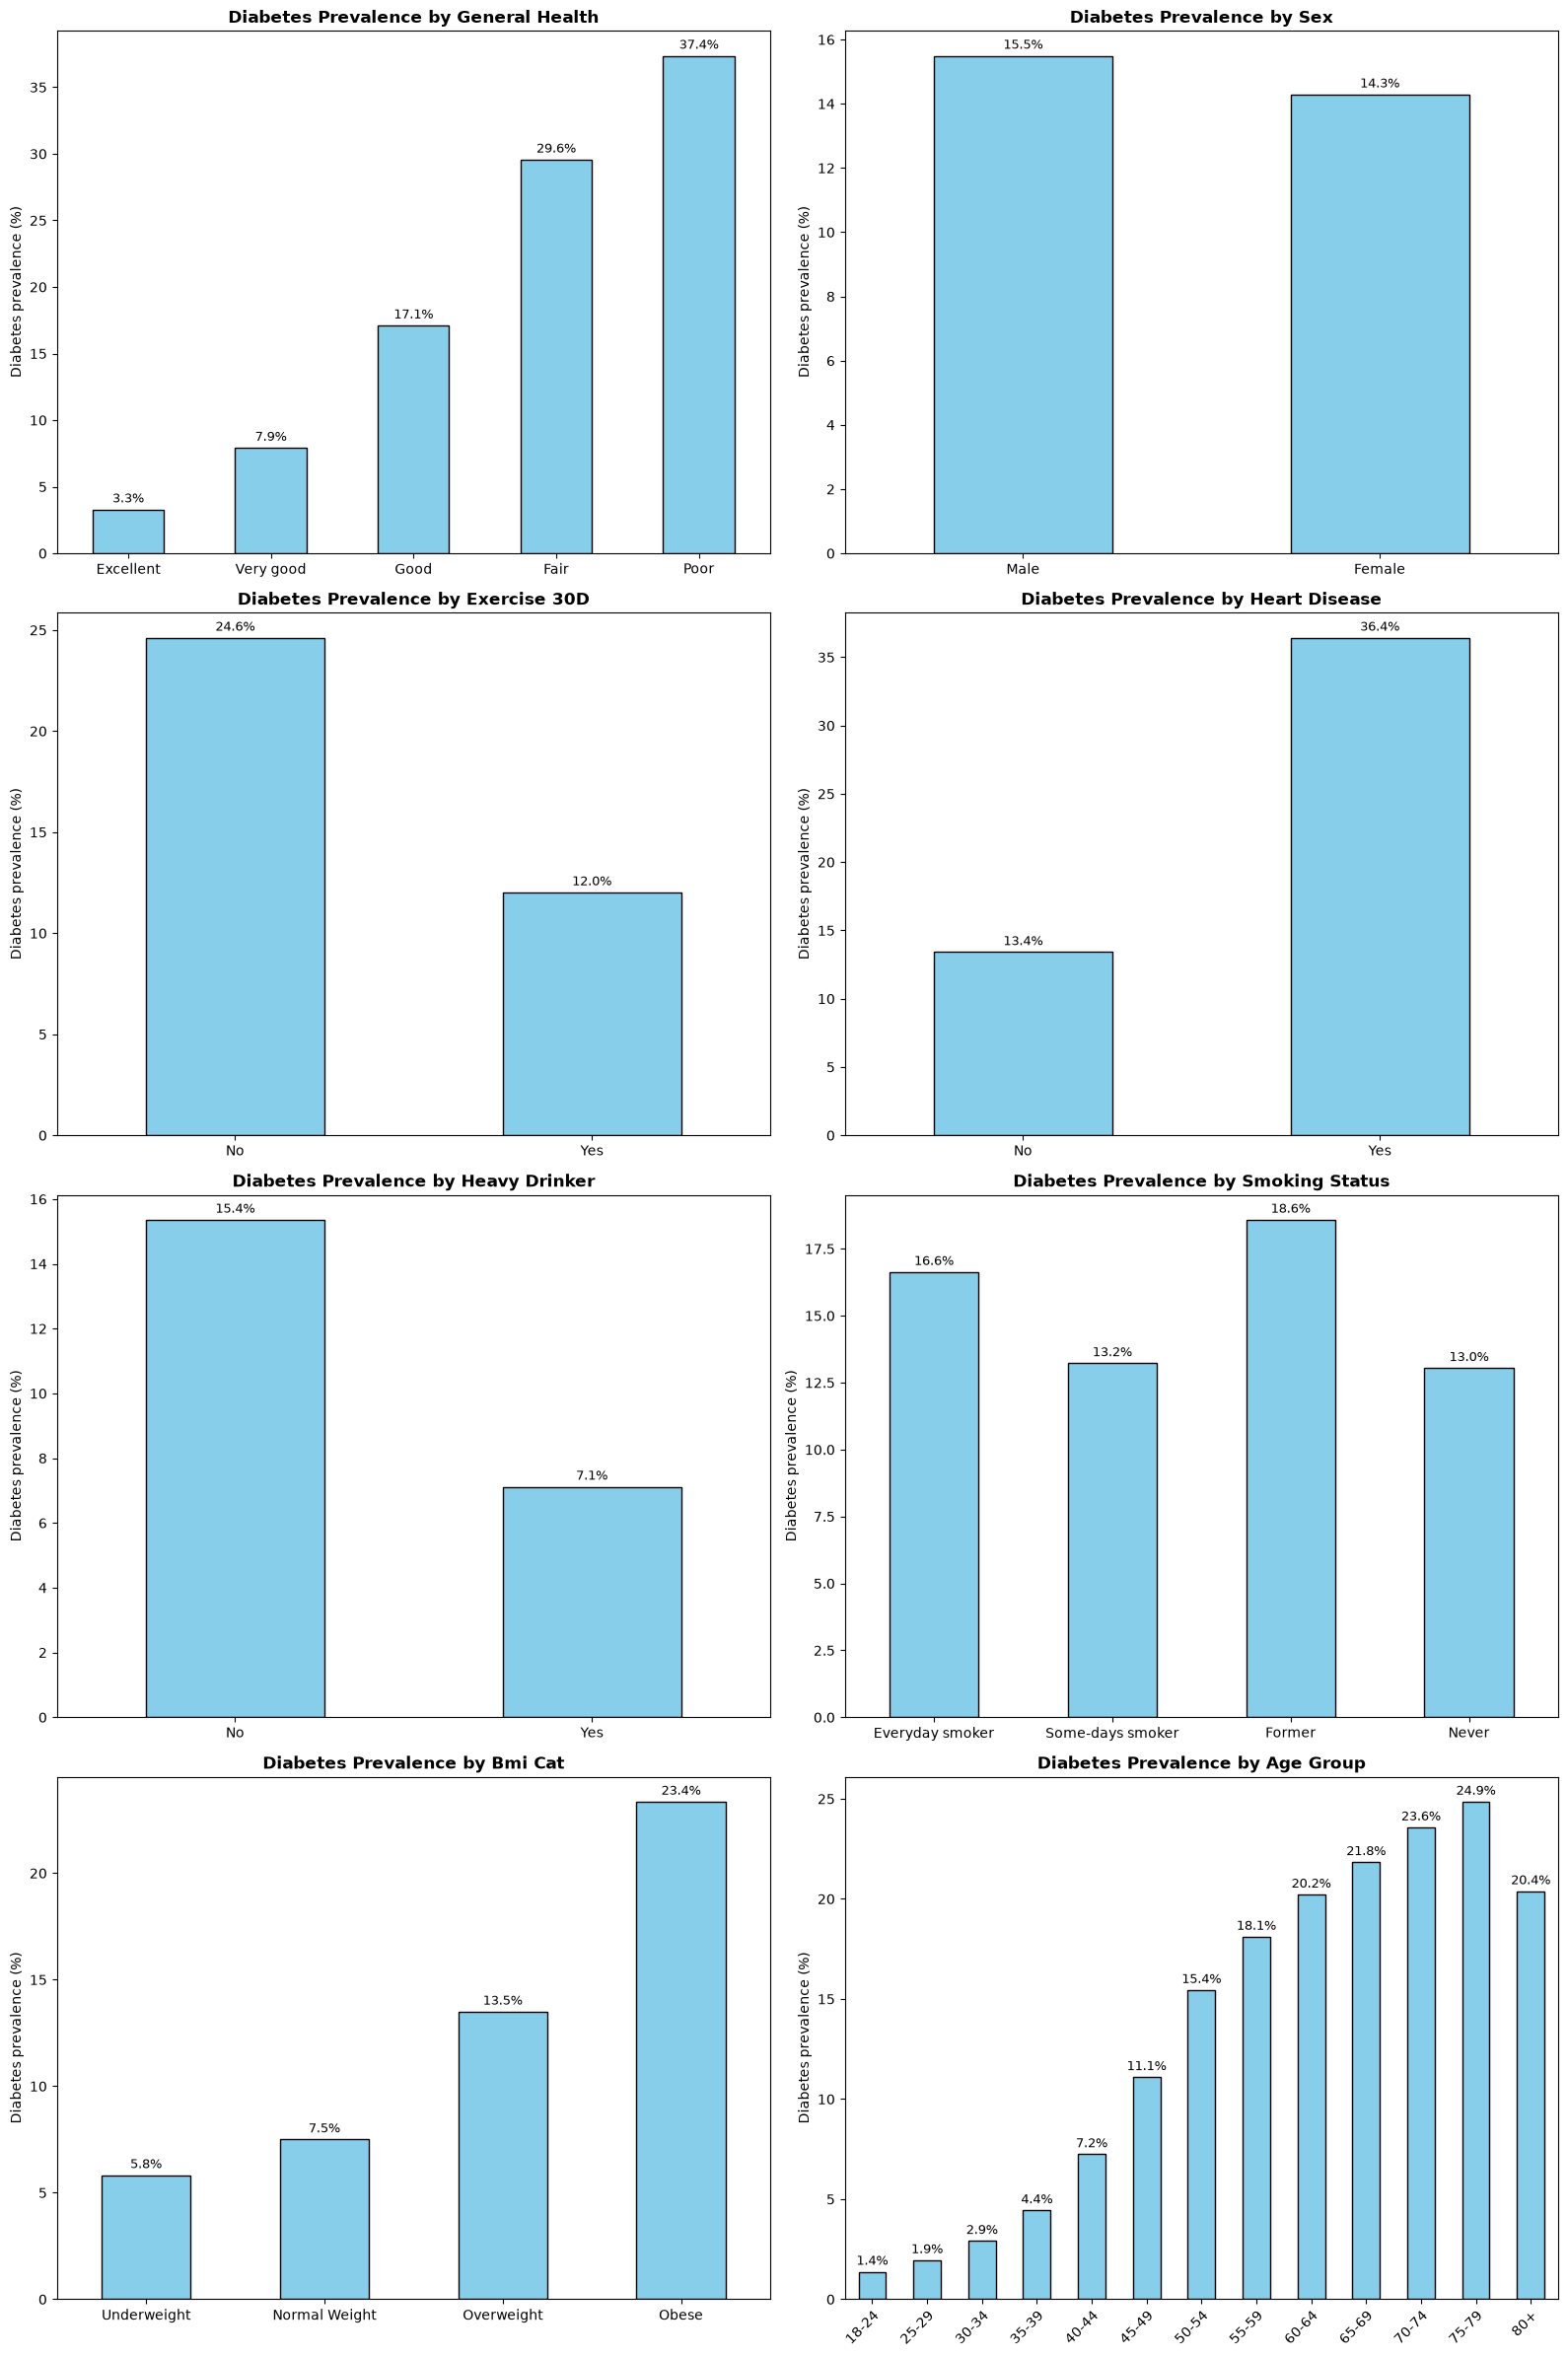

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 24))
axes = axes.flatten()

for i, (col, names) in enumerate(labels.items()):
    ax = axes[i]
    data = df.groupby(col)["diabetic"].mean() * 100
    
    if isinstance(names, dict):
        data.index = data.index.map(names)
    elif isinstance(names, list):
        data.index = names
    
    data.plot(kind="bar", ax=ax, color="skyblue", edgecolor="black")

    for container in ax.containers:
        ax.bar_label(container, fmt='{:.1f}%', padding=3, fontsize=9)

    ax.set_title(f"Diabetes Prevalence by {col.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    ax.set_ylabel("Diabetes prevalence (%)")
    ax.set_xlabel("") 

    rotation_angle = 45 if col == "age_group" else 0
    ax.tick_params(axis='x', rotation=rotation_angle)
    
    if rotation_angle > 0:
        plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")

plt.tight_layout()
plt.show()


In [29]:
# checking for correlation 
df.drop(columns=["diabetic"]).corr().round(2)

,general_health,exercise_30d,heart_disease,sex,age_group,bmi,bmi_cat,smoking_status,heavy_drinker
general_health,1.00,-0.28,0.20,0.02,0.13,0.22,0.18,-0.18,-0.02
exercise_30d,-0.28,1.00,-0.08,-0.07,-0.11,-0.14,-0.11,0.12,0.01
heart_disease,0.20,-0.08,1.00,-0.06,0.21,0.03,0.04,-0.06,-0.02
sex,0.02,-0.07,-0.06,1.00,0.07,-0.00,-0.05,0.05,-0.01
age_group,0.13,-0.11,0.21,0.07,1.00,-0.02,0.01,-0.08,-0.04
bmi,0.22,-0.14,0.03,-0.00,-0.02,1.00,0.83,0.01,-0.03
bmi_cat,0.18,-0.11,0.04,-0.05,0.01,0.83,1.00,0.01,-0.03
smoking_status,-0.18,0.12,-0.06,0.05,-0.08,0.01,0.01,1.00,-0.13
heavy_drinker,-0.02,0.01,-0.02,-0.01,-0.04,-0.03,-0.03,-0.13,1.00


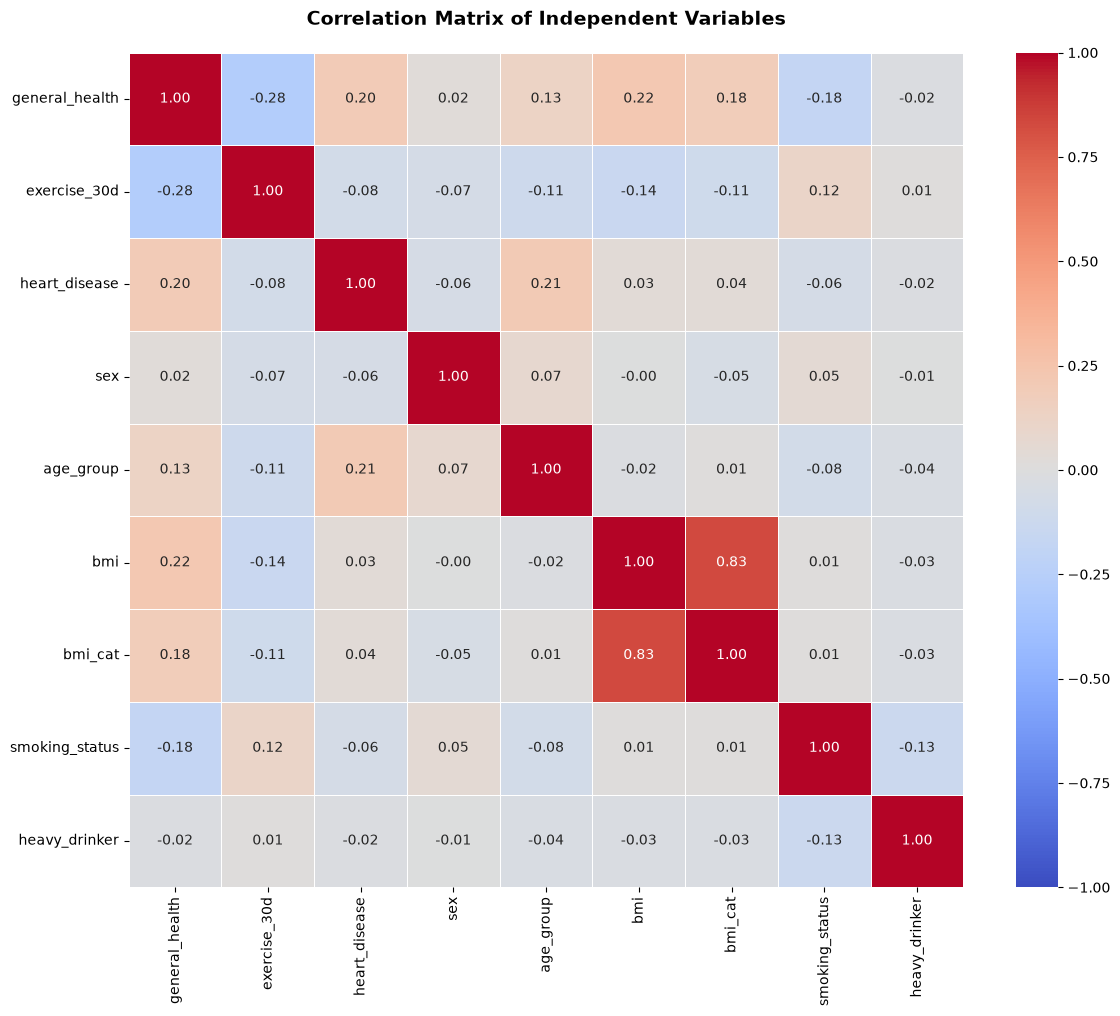

In [32]:
import seaborn as sns

# Set the size of your visualization canvas
plt.figure(figsize=(12, 10))

# Calculate the correlation matrix (excluding the target column)
corr_matrix = df.drop(columns=["diabetic"]).corr()

# Create the heatmap visual
sns.heatmap(
    corr_matrix, 
    annot=True,             
    fmt=".2f",            
    cmap="coolwarm",  
    vmin=-1, vmax=1,  
    linewidths=0.5,  
    square=True             
)

# Add clear titles
plt.title("Correlation Matrix of Independent Variables", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

plt.show()
